In [1]:
import pandas as pd
from pathlib import Path

In [2]:
PROC = Path("../data/processed")
df = pd.read_csv(PROC / "listings_final.csv", low_memory=False)
split = pd.read_csv(PROC / "split_assignment.csv")

In [3]:
df = df.merge(split, on=["city", "id"], how="left")
train = df[df["split"] == "train"]


In [4]:
print("train rows:", len(train))
print(train.groupby("city")["price"].agg(["count", "mean", "median", "max"]).round(1))

train rows: 33300
           count   mean  median      max
city                                    
Amsterdam   4863  344.0   285.0  11681.0
Barcelona  10498  265.7   195.0  11245.0
Berlin      6479  168.2   131.1  10025.0
Columbus    2081  217.7   164.5   3897.9


In [5]:
train = train.copy()
train["has_price"] = train["price"].notna()
print(train.groupby("city")["has_price"].agg(rows="size", with_price="sum", share="mean").round(3))

            rows  with_price  share
city                               
Amsterdam   8561        4863  0.568
Barcelona  12545       10498  0.837
Berlin      9868        6479  0.657
Columbus    2326        2081  0.895


In [6]:
train["no_price"] = ~train["has_price"]

print(train.groupby("no_price")[["accommodates", "availability_365",
                                 "number_of_reviews", "review_scores_rating"]].mean().round(2))

print(pd.crosstab(train["room_type"], train["no_price"], normalize="columns").round(3))

          accommodates  availability_365  number_of_reviews  \
no_price                                                      
False             3.74            204.18              80.48   
True              2.79             30.81              21.97   

          review_scores_rating  
no_price                        
False                     4.71  
True                      4.80  
no_price         False  True 
room_type                    
Entire home/apt  0.748  0.710
Hotel room       0.007  0.001
Private room     0.239  0.287
Shared room      0.007  0.001


In [7]:
train["avail_zero"] = train["availability_365"] == 0
print(train.groupby(["city", "no_price"])["avail_zero"].mean().unstack().round(3))

no_price   False  True 
city                   
Amsterdam  0.048  0.918
Barcelona  0.158  0.621
Berlin     0.016  0.800
Columbus   0.001  0.514


In [8]:
nz = train[train["no_price"] & train["avail_zero"]]
print("no-price + zero availability:", len(nz))
print("share with zero reviews in the last year:", (nz["number_of_reviews_ltm"] == 0).mean().round(3))

no-price + zero availability: 7504
share with zero reviews in the last year: 0.718


In [9]:
priced = train[train["has_price"]].copy()
print(priced.groupby("city")["price"].describe(percentiles=[.01, .25, .5, .75, .95, .99]).round(0))

             count   mean    std   min    1%    25%    50%    75%    95%  \
city                                                                       
Amsterdam   4863.0  344.0  354.0  38.0  74.0  200.0  285.0  406.0  746.0   
Barcelona  10498.0  266.0  414.0  13.0  27.0   99.0  195.0  290.0  594.0   
Berlin      6479.0  168.0  196.0  13.0  26.0   82.0  131.0  203.0  391.0   
Columbus    2081.0  218.0  217.0  24.0  34.0  102.0  164.0  266.0  532.0   

              99%      max  
city                        
Amsterdam  1160.0  11681.0  
Barcelona  2214.0  11245.0  
Berlin      694.0  10025.0  
Columbus   1024.0   3898.0  


In [10]:
cols = ["city", "price", "room_type", "accommodates", "bedrooms", "number_of_reviews", "availability_365"]
print(priced.sort_values("price", ascending=False)[cols].head(15))

            city     price        room_type  accommodates  bedrooms  \
39877  Amsterdam  11681.00  Entire home/apt             4       2.0   
30816  Amsterdam  11581.20  Entire home/apt             2       1.0   
23115  Barcelona  11245.03  Entire home/apt             2       1.0   
10887     Berlin  10025.00  Entire home/apt             7       2.0   
29732  Barcelona   7679.00  Entire home/apt            16      18.0   
27125  Barcelona   7293.00  Entire home/apt            16      12.0   
35252  Amsterdam   7200.00  Entire home/apt            16       7.0   
34936  Amsterdam   7200.00  Entire home/apt            16      17.0   
27156  Barcelona   6304.00  Entire home/apt            16      14.0   
26314  Barcelona   6129.00  Entire home/apt            16       2.0   
25198  Barcelona   5981.00  Entire home/apt            16      10.0   
27294  Barcelona   5930.00  Entire home/apt            16      29.0   
29731  Barcelona   5792.00  Entire home/apt            16      15.0   
33973 

In [11]:
def iqr_limit(s):
    q1, q3 = s.quantile([.25, .75])
    return q3 + 1.5 * (q3 - q1)

priced["iqr_limit"] = priced["city"].map(priced.groupby("city")["price"].apply(iqr_limit))
priced["p99"] = priced["city"].map(priced.groupby("city")["price"].quantile(.99))
priced["above_iqr"] = priced["price"] > priced["iqr_limit"]
priced["above_p99"] = priced["price"] > priced["p99"]
priced["price_per_person"] = priced["price"] / priced["accommodates"]

print(priced.groupby("city")[["above_iqr", "above_p99"]].sum())

band = priced[priced["above_iqr"] & ~priced["above_p99"]]
print("\nbetween IQR limit and 99th percentile:", len(band))
print(band[["price", "accommodates", "bedrooms", "number_of_reviews", "price_per_person"]].describe().round(1))

           above_iqr  above_p99
city                           
Amsterdam        268         49
Barcelona        564        105
Berlin           349         65
Columbus         113         21

between IQR limit and 99th percentile: 1054
        price  accommodates  bedrooms  number_of_reviews  price_per_person
count  1054.0        1054.0    1054.0             1054.0            1054.0
mean    817.2           7.5       3.6               46.8             143.5
std     379.9           4.1       2.2               83.3             105.0
min     384.5           1.0       0.0                0.0              25.1
25%     573.5           4.0       2.0                1.0              75.0
50%     728.0           6.0       3.0               11.0             115.4
75%     957.0          10.0       4.0               53.0             186.7
max    2214.0          16.0      15.0              852.0            1185.0


In [12]:
top = priced[priced["above_p99"]]
print("above 99th percentile:", len(top))
print("share with 0 reviews:", (top["number_of_reviews"] == 0).mean().round(3))
print("share with price_per_person > 500:", (top["price_per_person"] > 500).mean().round(3))
print(top[["price", "accommodates", "bedrooms", "number_of_reviews"]].describe().round(1))

p1 = priced.groupby("city")["price"].transform(lambda s: s.quantile(.01))
low = priced[priced["price"] <= p1]
print("\nbelow 1st percentile:", len(low))
print(low.groupby("room_type").size())
print(low[["price", "accommodates", "bedrooms"]].describe().round(1))

above 99th percentile: 240
share with 0 reviews: 0.479
share with price_per_person > 500: 0.067
         price  accommodates  bedrooms  number_of_reviews
count    240.0         240.0     240.0              240.0
mean    2433.5          10.6       6.5               19.5
std     1824.7           5.3       5.3               44.6
min      695.0           1.0       0.0                0.0
25%     1177.2           6.0       3.0                0.0
50%     2226.5          12.0       4.0                1.0
75%     2966.0          16.0      10.0               20.0
max    11681.0          16.0      29.0              328.0

below 1st percentile: 241
room_type
Entire home/apt      8
Hotel room           1
Private room       192
Shared room         40
dtype: int64
       price  accommodates  bedrooms
count  241.0         241.0     240.0
mean    31.1           1.8       1.7
std     16.9           1.6       2.0
min     12.8           1.0       0.0
25%     21.4           1.0       1.0
50%     24.6      

In [13]:
sus = priced[priced["price_per_person"] > 500]
print("price_per_person > 500:", len(sus))
print(sus.sort_values("price_per_person", ascending=False)[
    ["city", "price", "accommodates", "bedrooms", "room_type", "number_of_reviews"]].head(20))
for t in [300, 400, 500, 750]:
    print(t, int((priced["price_per_person"] > t).sum()))

price_per_person > 500: 32
            city     price  accommodates  bedrooms        room_type  \
30816  Amsterdam  11581.20             2       1.0  Entire home/apt   
23115  Barcelona  11245.03             2       1.0  Entire home/apt   
39877  Amsterdam  11681.00             4       2.0  Entire home/apt   
33973  Amsterdam   5706.00             2       1.0  Entire home/apt   
3532      Berlin   3837.63             2       0.0  Entire home/apt   
24259  Barcelona   3533.00             2       3.0  Entire home/apt   
26036  Barcelona   2961.61             2       1.0  Entire home/apt   
10887     Berlin  10025.00             7       2.0  Entire home/apt   
29174  Barcelona   1185.00             1       1.0     Private room   
23425  Barcelona   4463.00             4       2.0  Entire home/apt   
21405  Barcelona   4096.67             4       2.0  Entire home/apt   
25339  Barcelona   1000.00             1       1.0      Shared room   
3836      Berlin    982.23             1       1.0

In [14]:
import numpy as np

df["price_per_person"] = df["price"] / df["accommodates"]
df["price_suspect"] = df["price_per_person"] > 500

train = df[df["split"] == "train"].copy()
model_set = train[train["price"].notna() & ~train["price_suspect"]].copy()
model_set["log_price"] = np.log(model_set["price"])
print("rows used:", len(model_set))

feats = ["accommodates", "bedrooms", "beds", "bathrooms",
         "dist_center_km", "dist_nearest_landmark_km", "landmarks_1km", "landmarks_2km",
         "review_scores_rating", "review_scores_location", "number_of_reviews",
         "availability_365", "host_tenure_years"]

corr = model_set[feats + ["log_price"]].corr(method="spearman")["log_price"].drop("log_price")
print(corr.sort_values(ascending=False).round(2))

rows used: 23889
accommodates                0.53
bedrooms                    0.47
beds                        0.46
bathrooms                   0.28
landmarks_2km               0.20
number_of_reviews           0.17
landmarks_1km               0.16
review_scores_location      0.11
host_tenure_years           0.11
review_scores_rating        0.10
availability_365           -0.04
dist_nearest_landmark_km   -0.12
dist_center_km             -0.19
Name: log_price, dtype: float64


In [15]:
rows = []
for c, g in model_set.groupby("city"):
    r = g[feats + ["log_price"]].corr(method="spearman")["log_price"].drop("log_price")
    rows.append(r.rename(c))

by_city = pd.concat(rows, axis=1).round(2)
by_city["all_cities"] = corr.round(2)
print(by_city.sort_values("all_cities", ascending=False))

                          Amsterdam  Barcelona  Berlin  Columbus  all_cities
accommodates                   0.49       0.65    0.59      0.70        0.53
bedrooms                       0.55       0.51    0.47      0.63        0.47
beds                           0.38       0.61    0.49      0.67        0.46
bathrooms                      0.33       0.28    0.25      0.45        0.28
landmarks_2km                  0.14       0.12    0.16      0.13        0.20
number_of_reviews             -0.29       0.36    0.21      0.20        0.17
landmarks_1km                  0.14       0.05    0.15      0.13        0.16
host_tenure_years             -0.01       0.33    0.02     -0.06        0.11
review_scores_location         0.30       0.00    0.02      0.08        0.11
review_scores_rating           0.30       0.01    0.02      0.09        0.10
availability_365               0.08       0.04   -0.01      0.08       -0.04
dist_nearest_landmark_km      -0.06       0.00   -0.13     -0.12       -0.12

In [16]:
print(model_set.groupby(["city", "room_type"])["price"]
      .agg(count="size", median="median").round(0).unstack(0))

                    count                              median            \
city            Amsterdam Barcelona Berlin Columbus Amsterdam Barcelona   
room_type                                                                 
Entire home/apt      3444      8049   4656     1716     331.0     224.0   
Hotel room             20        63     54       24     187.0     235.0   
Private room         1374      2282   1716      336     175.0      76.0   
Shared room            17        88     48        2      63.0      56.0   

                                 
city            Berlin Columbus  
room_type                        
Entire home/apt  158.0    186.0  
Hotel room       130.0    161.0  
Private room      85.0     67.0  
Shared room       24.0     55.0  


city
Amsterdam    357
Barcelona    357
Berlin       357
Columbus     357
dtype: int64


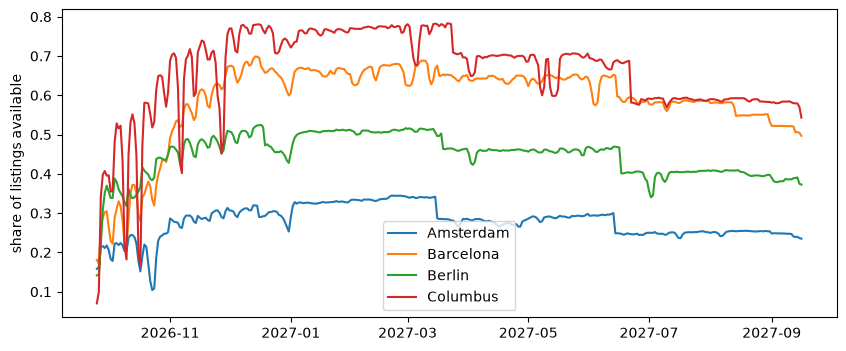

city   Amsterdam  Barcelona  Berlin  Columbus
month                                        
1           0.33       0.66    0.51      0.76
2           0.34       0.66    0.51      0.77
3           0.31       0.65    0.49      0.75
4           0.28       0.64    0.46      0.69
5           0.29       0.64    0.46      0.68
6           0.27       0.61    0.43      0.65
7           0.25       0.58    0.40      0.59
8           0.25       0.56    0.40      0.59
9           0.23       0.44    0.35      0.50
10          0.21       0.33    0.38      0.48
11          0.29       0.58    0.47      0.65
12          0.30       0.66    0.49      0.75


In [17]:
import matplotlib.pyplot as plt

cd = pd.read_csv(PROC / "city_daily_final.csv", parse_dates=["date"])
cd = cd[cd["in_common_period"]]
print(cd.groupby("city").size())

fig, ax = plt.subplots(figsize=(10, 4))
for c, g in cd.groupby("city"):
    ax.plot(g["date"], g["share_available"], label=c)
ax.set_ylabel("share of listings available")
ax.legend()
plt.show()

print(cd.pivot_table(index="month", columns="city", values="share_available").round(2))

In [18]:
cd = cd.sort_values(["city", "date"]).copy()
cd["diff"] = cd.groupby("city")["share_available"].diff()

big = cd.sort_values("diff").groupby("city").head(3)
print(big[["city", "date", "diff"]].sort_values(["city", "date"]).round(3))

           city       date   diff
29    Amsterdam 2026-10-16 -0.044
180   Amsterdam 2027-03-16 -0.055
270   Amsterdam 2027-06-14 -0.052
387   Barcelona 2026-10-09 -0.061
394   Barcelona 2026-10-16 -0.054
636   Barcelona 2027-06-15 -0.053
823      Berlin 2026-12-19 -0.047
913      Berlin 2027-03-19 -0.040
1003     Berlin 2027-06-17 -0.066
1112   Columbus 2026-10-09 -0.217
1119   Columbus 2026-10-16 -0.241
1140   Columbus 2026-11-06 -0.191


C:\Users\rokas\AppData\Local\Temp\ipykernel_38660\3530872610.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(big[["city", "date", "diff"]].sort_values(["city", "date"]).round(3))


In [19]:
stable = cd[(cd["date"] >= "2027-01-05") & (cd["date"] <= "2027-03-10")]
print(stable.pivot_table(index="day_of_week", columns="city", values="share_available").round(3))
print(stable.groupby(["city", "is_weekend"])["share_available"].mean().unstack().round(3))

city         Amsterdam  Barcelona  Berlin  Columbus
day_of_week                                        
0                0.335      0.660   0.511     0.773
1                0.334      0.661   0.509     0.771
2                0.334      0.663   0.509     0.767
3                0.333      0.662   0.507     0.760
4                0.332      0.662   0.507     0.753
5                0.333      0.660   0.509     0.753
6                0.335      0.661   0.511     0.767
is_weekend  False  True 
city                    
Amsterdam   0.334  0.333
Barcelona   0.662  0.661
Berlin      0.509  0.508
Columbus    0.768  0.753


In [20]:
nulls = train.isna().mean().sort_values(ascending=False)
print(nulls[nulls > 0].round(3).head(25))

neighbourhood_group_cleansed    0.327
estimated_revenue_l365d         0.282
price_per_person                0.282
price                           0.282
host_location                   0.182
review_scores_checkin           0.165
review_scores_location          0.165
review_scores_value             0.165
review_scores_accuracy          0.165
review_scores_cleanliness       0.164
review_scores_communication     0.164
first_review                    0.164
reviews_per_month               0.164
last_review                     0.164
review_scores_rating            0.164
minimum_maximum_nights          0.064
maximum_maximum_nights          0.064
minimum_nights                  0.064
maximum_nights                  0.064
minimum_minimum_nights          0.064
maximum_minimum_nights          0.064
beds                            0.030
has_availability                0.008
bedrooms                        0.001
bathrooms_text                  0.001
dtype: float64


In [21]:
model_set = train[train["price"].notna() & ~train["price_suspect"]].copy()
n2 = model_set.isna().mean().sort_values(ascending=False)
print(n2[n2 > 0].round(3).head(15))
print(train.groupby("city")["neighbourhood_group_cleansed"].apply(lambda s: s.isna().mean()).round(3))

neighbourhood_group_cleansed    0.290
host_location                   0.204
review_scores_rating            0.155
review_scores_accuracy          0.155
review_scores_cleanliness       0.155
review_scores_checkin           0.155
review_scores_communication     0.155
review_scores_location          0.155
last_review                     0.155
first_review                    0.155
review_scores_value             0.155
reviews_per_month               0.155
minimum_minimum_nights          0.084
maximum_nights                  0.084
maximum_minimum_nights          0.084
dtype: float64
city
Amsterdam    1.0
Barcelona    0.0
Berlin       0.0
Columbus     1.0
Name: neighbourhood_group_cleansed, dtype: float64
